In [72]:
import numpy as np
import pandas as pd

file_path = "../datasets/ames.csv"
csv = pd.read_csv(file_path)

dataframe = pd.DataFrame(csv)
dataframe.head()

,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YearSold,SaleType,SaleCondition,SalePrice
0,One_Story_1946_and_Newer_All_Styles,Residential_Low_Density,141.0,31770.0,Pave,No_Alley_Access,Slightly_Irregular,Lvl,AllPub,Corner,...,0.0,No_Pool,No_Fence,NaN,0.0,5,2010,WD,Normal,215000
1,One_Story_1946_and_Newer_All_Styles,Residential_High_Density,80.0,11622.0,Pave,No_Alley_Access,Regular,Lvl,AllPub,Inside,...,0.0,No_Pool,Minimum_Privacy,NaN,0.0,6,2010,WD,Normal,105000
2,One_Story_1946_and_Newer_All_Styles,Residential_Low_Density,81.0,14267.0,Pave,No_Alley_Access,Slightly_Irregular,Lvl,AllPub,Corner,...,0.0,No_Pool,No_Fence,Gar2,12500.0,6,2010,WD,Normal,172000
3,One_Story_1946_and_Newer_All_Styles,Residential_Low_Density,93.0,11160.0,Pave,No_Alley_Access,Regular,Lvl,AllPub,Corner,...,0.0,No_Pool,No_Fence,NaN,0.0,4,2010,WD,Normal,244000
4,Two_Story_1946_and_Newer,Residential_Low_Density,74.0,13830.0,Pave,No_Alley_Access,Slightly_Irregular,Lvl,AllPub,Inside,...,0.0,No_Pool,Minimum_Privacy,NaN,0.0,3,2010,WD,Normal,189900


In [73]:
features = [
    'GrLivArea', 'TotalBsmtSF', 'LotArea', 'YearBuilt', 'OverallQual', 'FullBath', 'BedroomAbvGr'
]

df = dataframe[features].copy()

df.head()

,GrLivArea,TotalBsmtSF,LotArea,YearBuilt,OverallQual,FullBath,BedroomAbvGr
0,1656.0,1080.0,31770.0,1960,Above_Average,1,3
1,896.0,882.0,11622.0,1961,Average,1,2
2,1329.0,1329.0,14267.0,1958,Above_Average,1,3
3,2110.0,2110.0,11160.0,1968,Good,2,3
4,1629.0,928.0,13830.0,1997,Average,2,3


In [74]:
# Check for null values

df.isnull().sum()

GrLivArea       0
TotalBsmtSF     0
LotArea         0
YearBuilt       0
OverallQual     0
FullBath        0
BedroomAbvGr    0
dtype: int64

In [75]:
# Check the distribution

df.skew(numeric_only=True)

GrLivArea        1.274110
TotalBsmtSF      1.150846
LotArea         12.820898
YearBuilt       -0.604462
FullBath         0.171952
BedroomAbvGr     0.305694
dtype: float64

In [76]:
# Applying Log transform for all features having |skew| > 1.5
# In this case it is 'LotArea'
df_new = df.copy()
df_new['LotArea'] = np.log1p(df_new['LotArea'])
df_new.skew(numeric_only=True)

GrLivArea       1.274110
TotalBsmtSF     1.150846
LotArea        -0.498335
YearBuilt      -0.604462
FullBath        0.171952
BedroomAbvGr    0.305694
dtype: float64

In [77]:
df_new.head()

,GrLivArea,TotalBsmtSF,LotArea,YearBuilt,OverallQual,FullBath,BedroomAbvGr
0,1656.0,1080.0,10.366309,1960,Above_Average,1,3
1,896.0,882.0,9.360741,1961,Average,1,2
2,1329.0,1329.0,9.565775,1958,Above_Average,1,3
3,2110.0,2110.0,9.320181,1968,Good,2,3
4,1629.0,928.0,9.534668,1997,Average,2,3


In [78]:
df_new_encoded = pd.get_dummies(df_new, drop_first=True)
df_new_encoded.head()

,GrLivArea,TotalBsmtSF,LotArea,YearBuilt,FullBath,BedroomAbvGr,OverallQual_Average,OverallQual_Below_Average,OverallQual_Excellent,OverallQual_Fair,OverallQual_Good,OverallQual_Poor,OverallQual_Very_Excellent,OverallQual_Very_Good,OverallQual_Very_Poor
0,1656.0,1080.0,10.366309,1960,1,3,False,False,False,False,False,False,False,False,False
1,896.0,882.0,9.360741,1961,1,2,True,False,False,False,False,False,False,False,False
2,1329.0,1329.0,9.565775,1958,1,3,False,False,False,False,False,False,False,False,False
3,2110.0,2110.0,9.320181,1968,2,3,False,False,False,False,True,False,False,False,False
4,1629.0,928.0,9.534668,1997,2,3,True,False,False,False,False,False,False,False,False


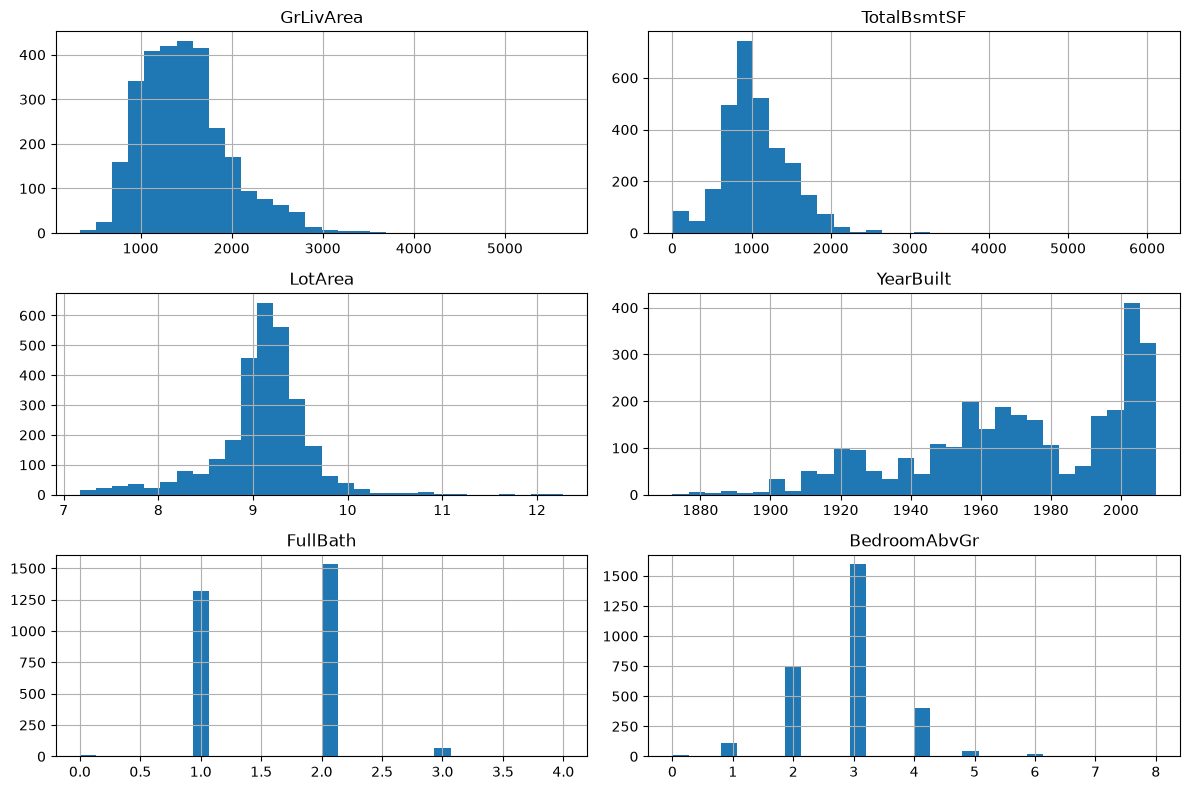

In [79]:
# Checking the data visually for patters

import matplotlib.pyplot as plt
import seaborn as sns

df_new_encoded.hist(bins=30, figsize=(12, 8))
plt.tight_layout()
plt.show()

In [80]:
# Preprocess the data

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
x_scaled = scaler.fit_transform(df_new_encoded)

In [ ]:
class KMeans:
    def __init__(self, k: int = 3, max_iter: int = 300, tolerance: float = 1e-4, random_state: int = 42):
        self.k: int = k
        self.max_iter: int = max_iter
        self.tolerance: float = tolerance
        self.random_state: int = random_state
        self.centroids: np.ndarray = None
        self.labels: np.ndarray = None
        self._inertia = None

    def optimize_centroids(self, X: np.ndarray, n_samples: int):
        for iteration in range(self.max_iter):
            distances: np.ndarray = np.linalg.norm(X[:, np.newaxis, :] - self.centroids[np.newaxis, :, :], axis=2)
            self.labels: np.ndarray = np.argmin(distances, axis=1)

            new_centroids = np.zeros_like(self.centroids)
            for j in range(self.k):
                cluster_points: np.ndarray = X[self.labels == j]
                if len(cluster_points) > 0:
                    new_centroids[j] = cluster_points.mean(axis=0)
                else:
                    new_centroids[j] = X[np.random.choice(n_samples)]

            shift = np.linalg.norm(new_centroids - self.centroids)
            self.centroids = new_centroids

            if shift < self.tolerance:
                break

    def final_inertia(self, X: np.ndarray):
        self._inertia = np.sum((X - self.centroids[self.labels]) ** 2)

    def fit(self, X: np.ndarray):
        np.random.seed(self.random_state)
        n_samples, n_features = X.shape

        initial_indices = np.random.choice(n_samples, size=self.k, replace=False)
        self.centroids = X[initial_indices].copy()

        self.optimize_centroids(X=X, n_samples=n_samples)
        self.final_inertia(X=X)

        return self

    def predict(self, X: np.ndarray):
        distances = np.linalg.norm(X[:, np.newaxis, :] - self.centroids[np.newaxis, :, :], axis=2)
        return np.argmin(distances, axis=1)

    def fit_predict(self, X: np.ndarray):
        self.fit(X)
        return self.labels

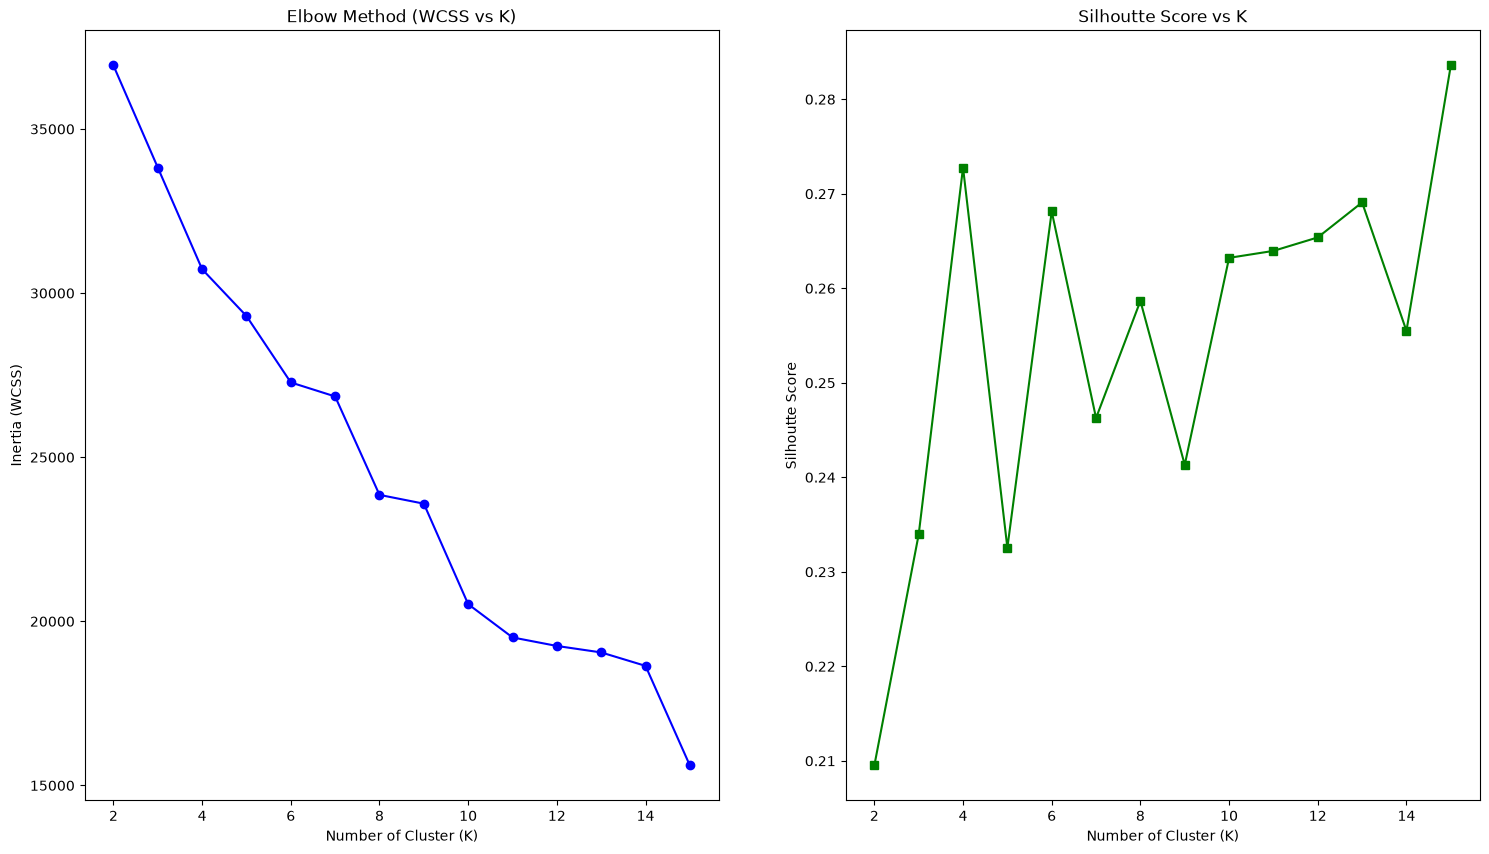

In [82]:
# Determining Optimal k

from sklearn.metrics import silhouette_score

k_range = range(2, 16) # 2 - 10
wcss_list = []
silhouette_list = []

for k in k_range:
    model = KMeans(k=k)
    model.fit(X=x_scaled)
    wcss_list.append(model._inertia)

    score = silhouette_score(x_scaled, model.labels)
    silhouette_list.append(score)

fig, ax = plt.subplots(1, 2, figsize=(18, 10))

ax[0].plot(k_range, wcss_list, marker="o", color="blue")
ax[0].set_title("Elbow Method (WCSS vs K)")
ax[0].set_xlabel("Number of Cluster (K)")
ax[0].set_ylabel("Inertia (WCSS)")

ax[1].plot(k_range, silhouette_list, marker="s", color="green")
ax[1].set_title("Silhoutte Score vs K")
ax[1].set_xlabel("Number of Cluster (K)")
ax[1].set_ylabel("Silhoutte Score")

plt.show()

In [83]:
optimal_k = 2
km = KMeans(k=optimal_k)
km.fit(X=x_scaled)
print(f"Cluster Sizes : {np.bincount(km.labels)}")
print(f"Inertia : {km._inertia}")
km_score = silhouette_score(x_scaled, km.labels)

Cluster Sizes : [1435 1495]
Inertia : 36935.24112598502


In [84]:
# Analysis

df_profile = df.copy()
df_profile['Cluster'] = km.labels
df_profile['SalePrice'] = dataframe['SalePrice']
df_profile = df_profile.drop(columns=['OverallQual'])
# print(df_profile.head())
profile_summary = df_profile.groupby('Cluster').mean().round(1)
profile_summary

,GrLivArea,TotalBsmtSF,LotArea,YearBuilt,FullBath,BedroomAbvGr,SalePrice
Cluster,,,,,,,
0,1808.3,1263.8,11406.5,1991.2,2.0,3.0,234018.2
1,1203.5,847.2,8939.8,1952.3,1.1,2.7,129710.0


In [85]:
# Validating against Sklearn's KMeans

from sklearn.cluster import KMeans as SkLearnMeans
from sklearn.metrics import adjusted_rand_score

sklearn_km = SkLearnMeans(n_clusters=optimal_k, random_state=42, n_init=10)
sklearn_km.fit(x_scaled)

sklearn_inertia = sklearn_km.inertia_
sklearn_silhoutte = silhouette_score(x_scaled, sklearn_km.labels_)

ari_score = adjusted_rand_score(km.labels, sklearn_km.labels_)

comparison_df = pd.DataFrame({
    'Metric': [
        'Inertia (WCSS)',
        'Silhouette Score',
        'Cluster Sizes',
        'Adjusted Rand Index (ARI)'
    ],
    'Custom KMeans': [
        f"{km._inertia:.2f}",
        f"{km_score:.4f}",
        f"{np.bincount(km.labels).tolist()}",
        "1.0000 (Self)"
    ],
    'Sklearn KMeans': [
        f"{sklearn_inertia:.2f}",
        f"{sklearn_silhoutte:.4f}",
        f"{np.bincount(sklearn_km.labels_).tolist()}",
        f"{ari_score:.4f}"
    ]
})

comparison_df

,Metric,Custom KMeans,Sklearn KMeans
0,Inertia (WCSS),36935.24,36935.24
1,Silhouette Score,0.2095,0.2095
2,Cluster Sizes,"[1435, 1495]","[1495, 1435]"
3,Adjusted Rand Index (ARI),1.0000 (Self),1.0000


PC1 explains 21.62% variance
PC2 explains 10.35% variance
Total 2D Variance Captured: 31.97%


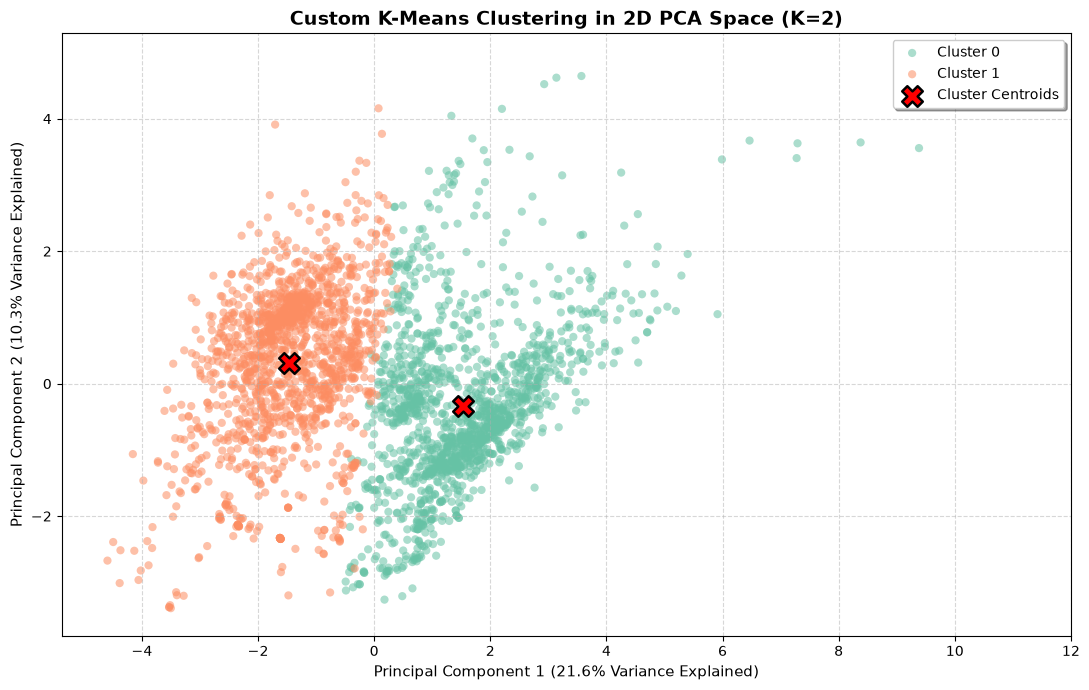

In [86]:
# ==========================================================
# 2. PCA Dimensionality Reduction & Cluster Visualization
# ==========================================================
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Fit PCA on the 15-dimensional standardized feature space
pca = PCA(n_components=2, random_state=42)
x_pca = pca.fit_transform(x_scaled)

# 2. IMPORTANT: Project the fitted 15D centroids into the same 2D PCA coordinate space!
centroids_pca = pca.transform(km.centroids)

var_pc1 = pca.explained_variance_ratio_[0] * 100
var_pc2 = pca.explained_variance_ratio_[1] * 100
total_var = var_pc1 + var_pc2

print(f"PC1 explains {var_pc1:.2f}% variance")
print(f"PC2 explains {var_pc2:.2f}% variance")
print(f"Total 2D Variance Captured: {total_var:.2f}%")

# 3. Plot the PCA Scatter
plt.figure(figsize=(11, 7), dpi=100)
palette = sns.color_palette("Set2", n_colors=km.k)

# Scatter plot each cluster
for cluster_id in range(km.k):
    cluster_mask = (km.labels == cluster_id)
    plt.scatter(
        x_pca[cluster_mask, 0],
        x_pca[cluster_mask, 1],
        label=f"Cluster {cluster_id}",
        color=palette[cluster_id],
        alpha=0.55,
        s=35,
        edgecolor='none'
    )

# 4. Plot the Cluster Centroids as prominent markers
plt.scatter(
    centroids_pca[:, 0],
    centroids_pca[:, 1],
    c='red',
    marker='X',
    s=220,
    edgecolor='black',
    linewidth=1.8,
    label='Cluster Centroids'
)

plt.title(f"Custom K-Means Clustering in 2D PCA Space (K={km.k})", fontsize=14, fontweight='bold')
plt.xlabel(f"Principal Component 1 ({var_pc1:.1f}% Variance Explained)", fontsize=11)
plt.ylabel(f"Principal Component 2 ({var_pc2:.1f}% Variance Explained)", fontsize=11)
plt.legend(loc='upper right', frameon=True, shadow=True)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()
